In [13]:
import ARIMA_ns
import numpy as np
import matplotlib.pyplot as plt
from ARIMA import ARIMA_fast,ARIMA_forecast
import jax.numpy as jnp
import jax
from fgivenx import plot_contours, plot_lines, plot_dkl
import arima_results as ar
from model_comparison_utils import ARIMA_model_comparison
import arima_mle 

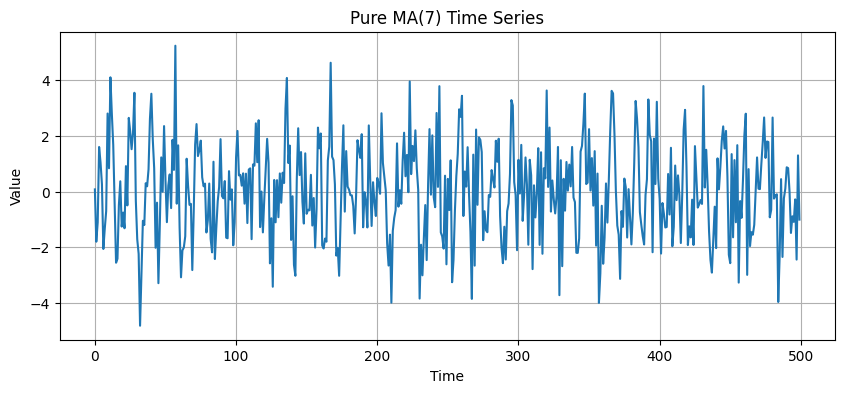

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 500
theta = np.random.uniform(-0.8, 0.8, 7)

# White noise
epsilon = np.random.normal(0, 1, n + 7)

# MA(7) process
y = np.zeros(n)

for t in range(n):
    y[t] = epsilon[t+7] + sum(
        theta[i] * epsilon[t+6-i] for i in range(7)
    )

# Plot
plt.figure(figsize=(10, 4))
plt.plot(y)
plt.title("Pure MA(7) Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.grid()
plt.show()

In [ ]:
data = np.loadtxt("ar2_sim_data.txt")
for seed in [5,10,15,20]:

 results = arima_mle.run_mle_bic(
    data=data,
    evidence_file="Heatmap Data/sim_ar2_logPs_normal.txt",
    likelihood_type='normal',
    seed=seed,
    n_random=5000, #more points to break degeneracy with ARIMA(1,0,1)
    top_k=10,
    maxiter=800,
    out_file=f"Heatmap Data/MLE runs/sim_ar2_mle_{seed}.txt"
 )
 file = ar.EvidenceResults(f"Heatmap Data/MLE runs/sim_ar2_mle_{seed}.txt",max_p=5)
 print(f"Seed {seed}: Minimum BIC at order {file.orders[np.argmin(file.BIC)]}")


Optimising ARIMA(0, 0, 1)...
NS max: -767.82208 | MLE: -767.82196 | Gain: 0.00012 | BIC: 1553.97166
Successful BFGS runs: 0/10

Optimising ARIMA(0, 0, 2)...
NS max: -710.29071 | MLE: -710.28412 | Gain: 0.00659 | BIC: 1445.00523
Successful BFGS runs: 0/10

Optimising ARIMA(0, 0, 3)...
NS max: -670.39807 | MLE: -670.38525 | Gain: 0.01282 | BIC: 1371.31675
Successful BFGS runs: 0/10

Optimising ARIMA(0, 0, 4)...
NS max: -660.66455 | MLE: -660.64587 | Gain: 0.01868 | BIC: 1357.94723
Successful BFGS runs: 0/10

Optimising ARIMA(0, 0, 5)...
NS max: -655.77692 | MLE: -655.70819 | Gain: 0.06873 | BIC: 1354.18111
Successful BFGS runs: 0/10

Optimising ARIMA(1, 0, 0)...
NS max: -647.29907 | MLE: -647.29456 | Gain: 0.00452 | BIC: 1319.02610
Successful BFGS runs: 0/10

Optimising ARIMA(1, 0, 1)...
NS max: -631.72375 | MLE: -631.70837 | Gain: 0.01538 | BIC: 1293.96299
Successful BFGS runs: 0/10

Optimising ARIMA(1, 0, 2)...
NS max: -629.48578 | MLE: -629.46069 | Gain: 0.02509 | BIC: 1295.57687
Suc

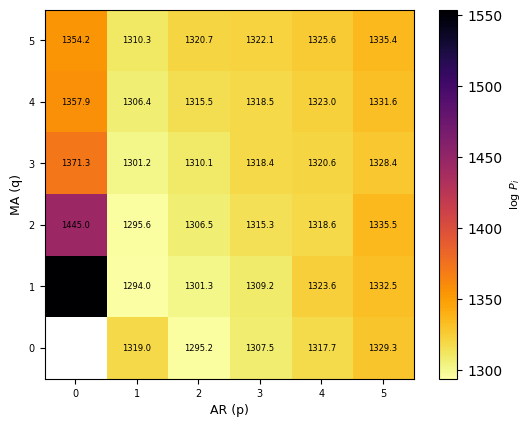

Minimum BIC at (1, 0, 1)


In [10]:
mle_sim = ar.EvidenceResults("Heatmap Data/sim_ar2_logPs_normal_mle.txt",max_p=5)
mle_sim.plot_evidence_heatmap(quantity="BIC")
plt.show()
print(f"Minimum BIC at {mle_sim.orders[np.argmin(mle_sim.BIC)]}")

In [4]:
log_P_pacf = ARIMA_model_comparison(data=y,max_p=8,max_q=8,d=0,num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=33,prior_type="normal",file_name='Heatmap Data/sim_ma7_logPs_pacf.txt')
log_P_pacf.run()

/var/folders/rr/1tj80lxs6qs82kdts2zyymz80000gn/T/ipykernel_1456/427528198.py:2: UserWarning: 'Heatmap Data/sim_ma7_logPs_pacf.txt' already exists and will be overwritten by this run. 
  log_P_pacf.run()


Running Nested Sampling for fitting ARIMA (0, 0, 1) model...


Dead points: 3700 dead points [00:02, 1566.44 dead points/s]


Finished Nested Sampling with a total runtime of : 2.74 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 1) : -964.8776937649293 ; Error : 0.2563096498283327
V : 0.682705 ; D0 Occam : 0.000 ; Net prior-volume effect : 0.382
Highest Evidence so far : -964.8776937649293 for order : (0, 0, 1)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (0, 0, 2) model...


Dead points: 4100 dead points [00:03, 1090.51 dead points/s]


Finished Nested Sampling with a total runtime of : 4.13 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 2) : -934.8876616484986 ; Error : 0.33325548901229896
V : 0.422895 ; D0 Occam : 0.000 ; Net prior-volume effect : 0.861
Highest Evidence so far : -934.8876616484986 for order : (0, 0, 2)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (0, 0, 3) model...


... (134 outputs left out)

Dead points: 9300 dead points [05:06, 30.37 dead points/s]


Finished Nested Sampling with a total runtime of : 306.73 seconds
----------------------x-------------------x---------------------x------
Evidence for (7, 0, 7) : -918.1275218164203 ; Error : 0.5254696530727415
V : 1.986915e-05 ; D0 Occam : -3.059 ; Net prior-volume effect : 7.767
Highest Evidence so far : -905.3539603122721 for order : (0, 0, 7)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (7, 0, 8) model...


Dead points: 2350 dead points [01:29, 26.12 dead points/s]


KeyboardInterrupt: 

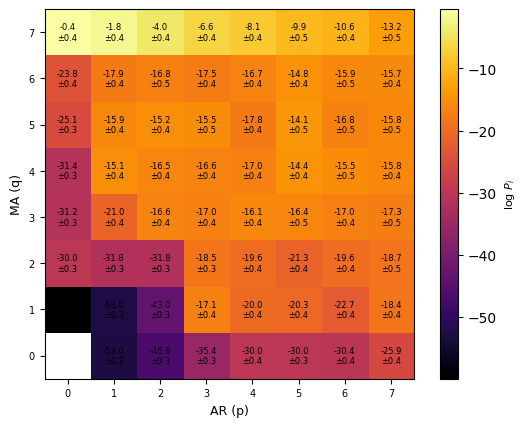

In [13]:
ma_evidences = ar.EvidenceResults("Heatmap Data/sim_ma7_logPs_pacf.txt",max_p=7)
ma_evidences.plot_evidence_heatmap()
plt.show()

In [14]:
len(y)

500

In [20]:
neighbouring_orders = [(0,0,10),(0,0,9),(0,0,8),(0,0,7),(0,0,6),(0,0,5),(0,0,4),(0,0,3),(0,0,2),(0,0,1)]
MA_n = [y,y[:250],y[:125],y[:60]]
seeds = [10,20,30]
evidences = []
errors = []
for n in MA_n:
    for seed in seeds:
        print("************************************************")
        print(f"----- Data length {len(n)} and seed: {seed} -----")
        print("************************************************")
        for order in neighbouring_orders:
            
            model = ARIMA_ns.ARIMA_Nested_Sampler(data=n,order=order,num_live=200,num_delete=50,seed=seed,
                                                  mu_mean=0,mu_scale=5)
            evidences.append(model.log_evidence)
            errors.append(model.log_evidence_err)
            
            

************************************************
----- Data length 500 and seed: 10 -----
************************************************
Running Nested Sampling for fitting ARIMA (0, 0, 10) model...


Dead points: 7000 dead points [01:23, 83.55 dead points/s]


Finished Nested Sampling with a total runtime of : 84.02 seconds
Running Nested Sampling for fitting ARIMA (0, 0, 9) model...


Dead points: 6700 dead points [01:03, 104.80 dead points/s]


Finished Nested Sampling with a total runtime of : 64.30 seconds
Running Nested Sampling for fitting ARIMA (0, 0, 8) model...


Dead points: 6500 dead points [00:48, 135.11 dead points/s]


... (231 outputs left out)

Dead points: 3050 dead points [00:02, 1430.03 dead points/s]


Finished Nested Sampling with a total runtime of : 2.38 seconds
Running Nested Sampling for fitting ARIMA (0, 0, 1) model...


Dead points: 2800 dead points [00:01, 1851.01 dead points/s]

Finished Nested Sampling with a total runtime of : 1.68 seconds


In [26]:
evidences = np.array(evidences).reshape(4, 3, 10)
errors = np.array(errors).reshape(4, 3, 10)

In [40]:
for i in range(4):
    for j in range(3):
        idx = np.argmax(evidences[i, j])
        print(f"Dataset {i+1}, Seed {j+1}: Max evidence = {evidences[i,j,idx]:.4f} ± {errors[i,j,idx]:.4f} (Order {idx})")

Dataset 1, Seed 1: Max evidence = -903.1908 ± 0.4035 (Order 3)
Dataset 1, Seed 2: Max evidence = -902.6161 ± 0.3564 (Order 3)
Dataset 1, Seed 3: Max evidence = -903.3248 ± 0.3763 (Order 3)
Dataset 2, Seed 1: Max evidence = -456.8580 ± 0.3258 (Order 3)
Dataset 2, Seed 2: Max evidence = -456.8353 ± 0.3510 (Order 3)
Dataset 2, Seed 3: Max evidence = -457.0441 ± 0.2970 (Order 3)
Dataset 3, Seed 1: Max evidence = -237.0064 ± 0.2877 (Order 3)
Dataset 3, Seed 2: Max evidence = -236.5552 ± 0.2678 (Order 3)
Dataset 3, Seed 3: Max evidence = -236.3435 ± 0.2803 (Order 3)
Dataset 4, Seed 1: Max evidence = -123.0356 ± 0.2951 (Order 0)
Dataset 4, Seed 2: Max evidence = -124.0879 ± 0.2722 (Order 3)
Dataset 4, Seed 3: Max evidence = -124.3678 ± 0.2511 (Order 3)


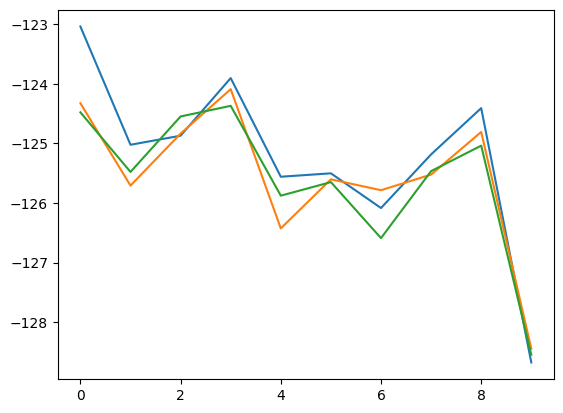

In [49]:


plt.plot(evidences[3][0])
plt.plot(evidences[3][1])
plt.plot(evidences[3][2])

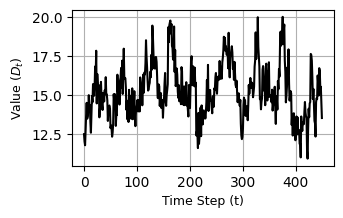

In [ ]:
phi_1 = 0.6
phi_2 = 0.3

# Constant term
c = 1.5

# Standard deviation of the white noise
noise_std = 1.0

# Number of data points to generate
n_samples = 500

# Set a seed for reproducibility
np.random.seed(42)

# --------------------------------------------------
# 2. Generate the Time Series
# --------------------------------------------------

# Initialize the series array with zeros
series = np.zeros(n_samples)

# Generate the white noise
noise = np.random.normal(0, noise_std, n_samples)


series[0] = c / (1 - phi_1 - phi_2)
series[1] = c / (1 - phi_1 - phi_2)

# Generate the rest of the series using a loop
for t in range(2, n_samples):
    # Apply the AR(2) formula
    series[t] = c + phi_1 * series[t-1] + phi_2 * series[t-2] + noise[t]

#Discard the first 50 pts (burn-in)
series = series[50:]

# --------------------------------------------------
# 3. Plot the Generated Time Series
# --------------------------------------------------
fig_width_pt = 244.0 # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = 0.6
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height =fig_width*golden_mean
figure = plt.figure(figsize=(fig_width, fig_height))
plt.plot(series,color='black')

plt.xlabel(r'Time Step (t)',fontsize=9)
plt.ylabel(r'Value ($D_t$)',fontsize=9)
plt.grid(True)
plt.show()
#np.savetxt("ar2_sim_data.txt",series)

In [2]:
series = np.loadtxt("ar2_sim_data.txt")
#log_P = ARIMA_model_comparison(data=series,max_p=5,max_q=5,d=0,num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=33,prior_type="normal",file_name='Heatmap Data/sim_ar2_logPs_normal.txt')
#log_P.run()

In [4]:
log_P_pacf = ARIMA_model_comparison(data=series,max_p=5,max_q=5,d=0,num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=33,prior_type="pacf",file_name='Heatmap Data/sim_ar2_logPs_pacf.txt')
log_P_pacf.run()

Running Nested Sampling for fitting ARIMA (0, 0, 1) model...


/var/folders/rr/1tj80lxs6qs82kdts2zyymz80000gn/T/ipykernel_8528/1104297488.py:1: UserWarning: 'Heatmap Data/sim_ar2_logPs_pacf.txt' already exists and will be overwritten by this run. If you meant to keep it, rename/move it (or change file_name) before calling .run().
  log_P_pacf = ARIMA_model_comparison(data=series,max_p=5,max_q=5,d=0,num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=33,prior_type="pacf",file_name='Heatmap Data/sim_ar2_logPs_pacf.txt')
/var/folders/rr/1tj80lxs6qs82kdts2zyymz80000gn/T/ipykernel_8528/1104297488.py:2: UserWarning: 'Heatmap Data/sim_ar2_logPs_pacf.txt' already exists and will be overwritten by this run. 
  log_P_pacf.run()
Dead points: 3750 dead points [00:03, 955.84 dead points/s] 


Finished Nested Sampling with a total runtime of : 4.45 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 1) : -782.3413838767846 ; Error : 0.2512780285890152
V : 1.0 ; D0 Occam : 0.000 ; Net prior-volume effect : 0.000
Highest Evidence so far : -782.3413838767846 for order : (0, 0, 1)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (0, 0, 2) model...


Dead points: 4300 dead points [00:05, 764.89 dead points/s] 


Finished Nested Sampling with a total runtime of : 6.27 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 2) : -727.9559343398341 ; Error : 0.32768420216102573
V : 1.0 ; D0 Occam : 0.000 ; Net prior-volume effect : 0.000
Highest Evidence so far : -727.9559343398341 for order : (0, 0, 2)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (0, 0, 3) model...


Dead points: 4800 dead points [00:07, 631.74 dead points/s]


... (61 outputs left out)

Dead points: 7700 dead points [01:45, 73.20 dead points/s]


Finished Nested Sampling with a total runtime of : 105.99 seconds
----------------------x-------------------x---------------------x------
Evidence for (5, 0, 4) : -663.2717283916512 ; Error : 0.44251454606883023
V : 1.0 ; D0 Occam : -4.557 ; Net prior-volume effect : -4.557
Highest Evidence so far : -649.615932937596 for order : (2, 0, 0)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (5, 0, 5) model...


Dead points: 8150 dead points [02:06, 64.64 dead points/s]


Finished Nested Sampling with a total runtime of : 126.93 seconds
----------------------x-------------------x---------------------x------
Evidence for (5, 0, 5) : -664.9355415389484 ; Error : 0.44895060444148666
V : 1.0 ; D0 Occam : -4.558 ; Net prior-volume effect : -4.558
Highest Evidence so far : -649.615932937596 for order : (2, 0, 0)
----------------------x-------------------x----------------------x-----


Running Nested Sampling for fitting ARIMA (2, 0, 0) model...


Dead points: 27800 dead points [00:33, 838.71 dead points/s]


Finished Nested Sampling with a total runtime of : 33.92 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 33.92 seconds
----------------------------------------------------
Posterior mean for phi_1 : 0.5950415396385907
Posterior mean for phi_2 : 0.2618352109765975
Posterior mean for sigma : 0.9877526763153773
Posterior mean for mu : 15.314121076865593
Posterior mean for init_y_1 : 9.264700971001679
Posterior mean for init_y_2 : 18.67287537933554
---------------------------------------------------
Log Evidence: -651.02 ± 0.12
-------x----------------x-------------x------------


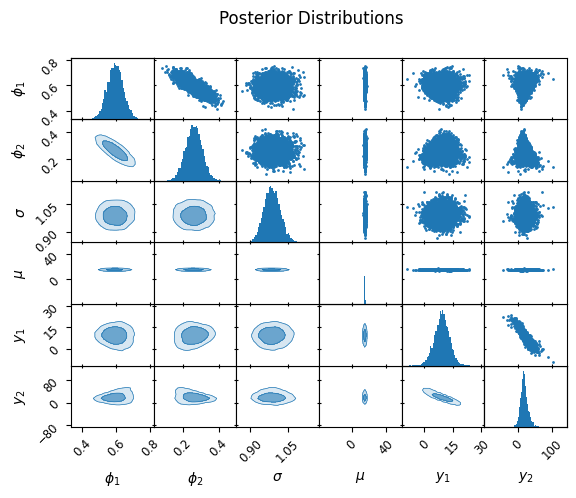

In [7]:
model = ARIMA_ns.ARIMA_Nested_Sampler(data=series,order=(2,0,0),num_live=1000,num_delete=50,mu_mean=0,mu_scale=50,seed=33,prior_type="normal")
model.summary()

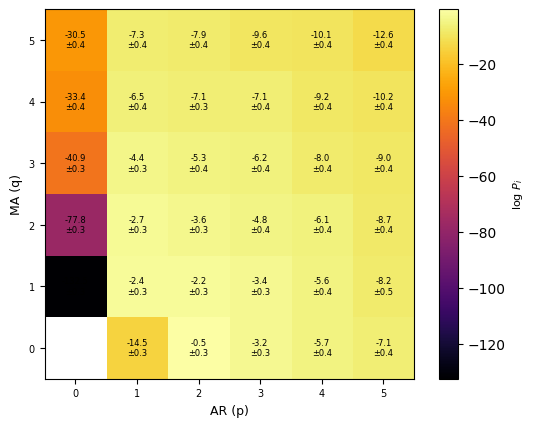

In [44]:
sim_heatmap_data = ar.EvidenceResults("Heatmap Data/sim_ar2_logPs_normal.txt",max_p=5)
sim_heatmap_data.plot_evidence_heatmap()
plt.show()

In [56]:
logP = sim_heatmap_data.log_posteriors 
logP_err = sim_heatmap_data.evidence_err
print(fr"Max logP for {sim_heatmap_data.orders[np.argmax(logP)]} with logP {max(logP)} and error {logP_err[np.argmax(logP)]}")

Max logP for (2, 0, 0) with logP -0.531775755110516 and error 0.3114857366366344


In [8]:
samples = model.posterior_samples
samples.to_csv('NS Chains/simulated_ar2_samples_new.csv')

In [28]:
import numpy as np

def generate_arma11_trend(n, phi=0.5, theta=-0.2, mu=0.0, beta=0.01,
                          sigma=1.0, x0=0.0, seed=None):
    """
    Generate an ARMA(1,1) time series with a linear trend.

    Model:
        x_t = mu + beta*t + phi*x_{t-1} + eps_t + theta*eps_{t-1}

    Parameters
    ----------
    n : int
        Number of time steps.
    phi : float
        AR(1) coefficient.
    theta : float
        MA(1) coefficient.
    mu : float
        Intercept term.
    beta : float
        Linear trend slope.
    sigma : float
        Noise standard deviation.
    x0 : float
        Initial value x_0.
    seed : int or None
        Random seed.

    Returns
    -------
    x : ndarray
        Simulated ARMA(1,1) process with trend.
    """

    rng = np.random.default_rng(seed)
    eps = rng.normal(scale=sigma, size=n)

    x = np.zeros(n)
    x[0] = x0 + mu + beta * 0 + eps[0]  # initialization

    for t in range(1, n):
        x[t] = (
            mu
            + beta * t
            + phi * x[t-1]
            + eps[t]
            + theta * eps[t-1]
        )

    return x


ts = generate_arma11_trend(
    n=800,
    phi=0.6,
    theta=-0.4,
    mu=2.0,
    beta=0.02,
    sigma=1.0,
    seed=123
)
ts=ts[300:]
np.savetxt("simulated_trend_data.txt",ts)

Text(0, 0.5, 'Value')

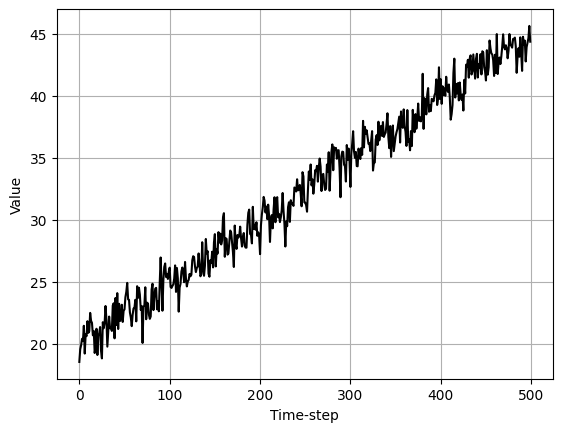

In [29]:
ts = np.loadtxt("simulated_trend_data.txt")
plt.plot(ts,color='black')
plt.grid()
plt.xlabel('Time-step')
plt.ylabel('Value')

Running Nested Sampling for fitting ARIMA (1, 0, 1) model...


Dead points: 5650 dead points [00:10, 520.34 dead points/s]


Finished Nested Sampling with a total runtime of : 11.63 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 11.63 seconds
----------------------------------------------------
Posterior mean for phi_1 : 0.9982271087685078
Posterior mean for theta_1 : -0.8377549656169038
Posterior mean for sigma : 1.0826999157283403
Posterior mean for mu : 62.70314787458244
Posterior mean for init_y_1 : 19.64369071186791
---------------------------------------------------
Log Evidence: -770.41 ± 0.37
-------x----------------x-------------x------------


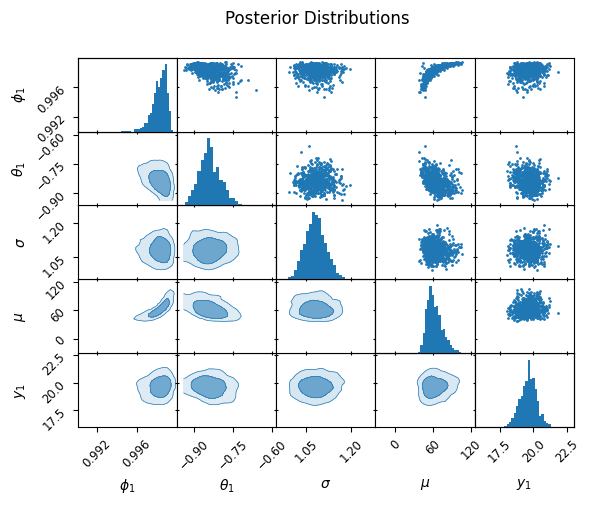

In [30]:
model1 = ARIMA_ns.ARIMA_Nested_Sampler(data=ts,order=(1,0,1),num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=3)
model1.summary()

Running Nested Sampling for fitting ARIMA (1, 1, 1) model...


Dead points: 6050 dead points [00:09, 607.23 dead points/s]


Finished Nested Sampling with a total runtime of : 10.81 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 10.81 seconds
----------------------------------------------------
Posterior mean for phi_1 : 0.197010893443403
Posterior mean for theta_1 : -0.9658796301172863
Posterior mean for sigma : 1.0554275137226838
Posterior mean for mu : 0.04947173373087599
Posterior mean for init_y_1 : 6.770200029007402
---------------------------------------------------
Log Evidence: -758.06 ± 0.43
-------x----------------x-------------x------------


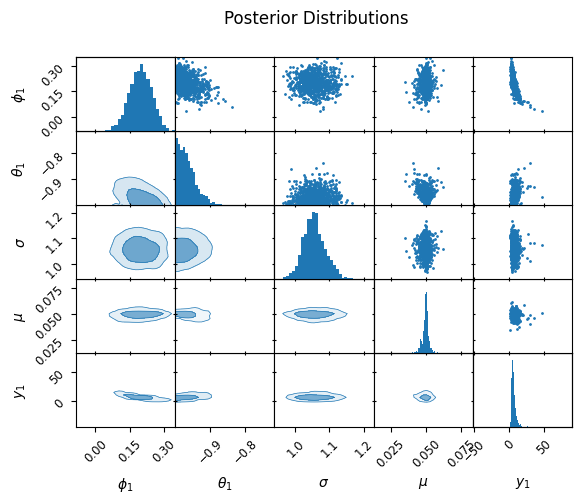

In [31]:
model2 = ARIMA_ns.ARIMA_Nested_Sampler(data=ts,order=(1,1,1),num_live=200,num_delete=50,mu_mean=0,mu_scale=30,seed=3)
model2.summary()

Running Nested Sampling for fitting ARIMA (1, 2, 1) model...


Dead points: 7170 dead points [00:13, 548.71 dead points/s]


Finished Nested Sampling with a total runtime of : 13.49 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 13.49 seconds
----------------------------------------------------
Posterior mean for phi_1 : -0.43652946900008854
Posterior mean for theta_1 : -0.9923755211633875
Posterior mean for sigma : 1.2050907445492296
Posterior mean for mu : -1.2238916090709488e-05
Posterior mean for init_y_1 : 3.2242081295005955
---------------------------------------------------
Log Evidence: -829.68 ± 0.36
-------x----------------x-------------x------------


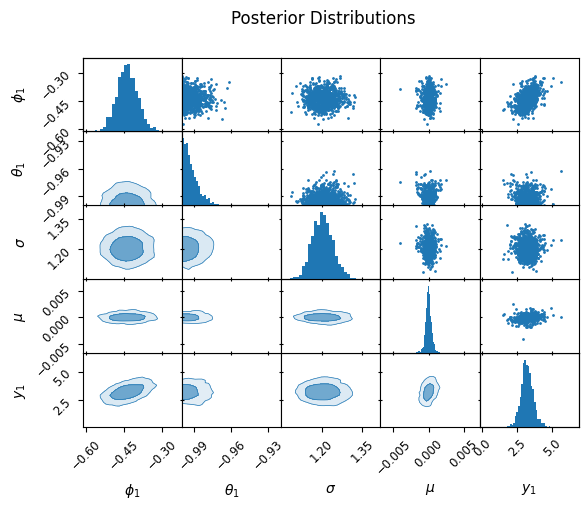

In [32]:
model3 = ARIMA_ns.ARIMA_Nested_Sampler(data=ts,order=(1,2,1),num_live=200,num_delete=30,mu_mean=0,mu_scale=50,seed=3)
model3.summary()

Running Nested Sampling for fitting ARIMA (1, 3, 1) model...


Dead points: 6960 dead points [00:12, 548.88 dead points/s]


Finished Nested Sampling with a total runtime of : 13.03 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 13.03 seconds
----------------------------------------------------
Posterior mean for phi_1 : -0.6492422914092403
Posterior mean for theta_1 : -0.9925213350802338
Posterior mean for sigma : 1.733380544842982
Posterior mean for mu : 2.2307574718247868e-05
Posterior mean for init_y_1 : -1.7537244884655943
---------------------------------------------------
Log Evidence: -1009.78 ± 0.39
-------x----------------x-------------x------------


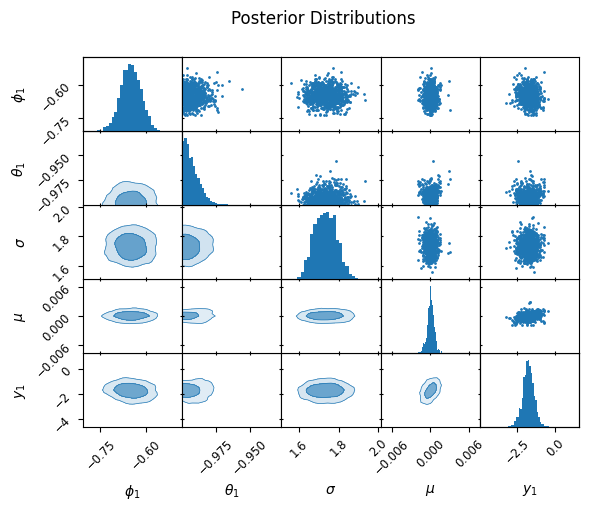

In [33]:
model4 = ARIMA_ns.ARIMA_Nested_Sampler(data=ts,order=(1,3,1),num_live=200,num_delete=30,mu_mean=0,mu_scale=50,seed=3)
model4.summary()

Running Nested Sampling for fitting ARIMA (1, 4, 1) model...


Dead points: 6870 dead points [00:12, 552.88 dead points/s]


Finished Nested Sampling with a total runtime of : 12.74 seconds
||NESTED SAMPLING SUMMARY RESULTS||
----------------------------------------------------
Nested sampling runtime: 12.74 seconds
----------------------------------------------------
Posterior mean for phi_1 : -0.7455700322139297
Posterior mean for theta_1 : -0.9926284200444861
Posterior mean for sigma : 2.748651720033365
Posterior mean for mu : -2.062504598781247e-05
Posterior mean for init_y_1 : 2.0640188320318518
---------------------------------------------------
Log Evidence: -1240.22 ± 0.39
-------x----------------x-------------x------------


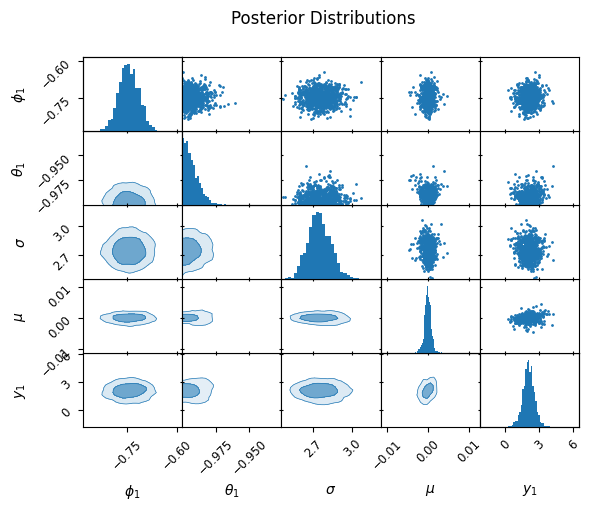

In [34]:
model5 = ARIMA_ns.ARIMA_Nested_Sampler(data=ts,order=(1,4,1),num_live=200,num_delete=30,mu_mean=0,mu_scale=50,seed=3)
model5.summary()

In [35]:
evidences = [model1.log_evidence,model2.log_evidence,model3.log_evidence,model4.log_evidence,model5.log_evidence]
err = [model1.log_evidence_err,model2.log_evidence_err,model3.log_evidence_err,model4.log_evidence_err,model5.log_evidence_err]

In [36]:
from scipy.special import logsumexp
normalization = logsumexp(evidences)
log_probs = evidences - normalization
print("Model log posterior probabilities for ARMA(1,d,1) for d=0,1,2,3,4")
print(log_probs,err)

Model log posterior probabilities for ARMA(1,d,1) for d=0,1,2,3,4
[-1.23455968e+01 -4.34886954e-06 -7.16179961e+01 -2.51721384e+02
 -4.82162729e+02] [np.float64(0.33482792999968375), np.float64(0.30044332238087046), np.float64(0.4184957743591272), np.float64(0.39563790463280346), np.float64(0.37085995675783345)]


-4.348869538262079e-06


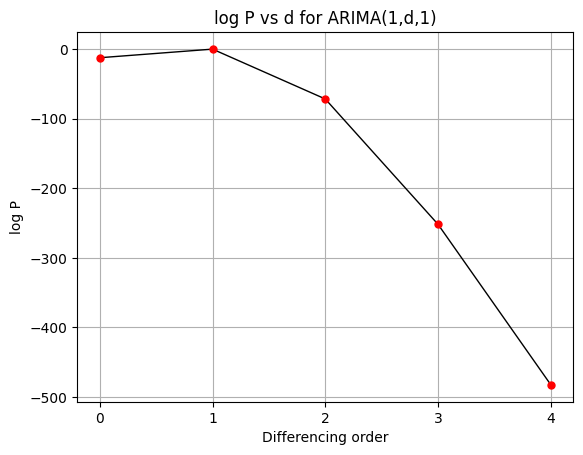

In [37]:
print(max(log_probs))
x = [0,1,2,3,4]
plt.errorbar(x,log_probs,yerr=err,marker="o",ms=5,capsize=2,color="red",lw=0)
plt.plot(x,log_probs,color="black",lw=1)

plt.xticks([0,1,2,3,4])
plt.xlabel("Differencing order")
plt.ylabel("log P")
plt.title("log P vs d for ARIMA(1,d,1)")
plt.grid()

In [3]:
##Benchmarking with simulated data 
import time

#first varying n_live for fixed N

phi_1 = 0.6
phi_2 = 0.3


c = 1.5

noise_std = 1.0

n_samples = 1000
np.random.seed(42)


series_benchmark = np.zeros(n_samples)

noise = np.random.normal(0, noise_std, n_samples)


series_benchmark[0] = c / (1 - phi_1 - phi_2)
series_benchmark[1] = c / (1 - phi_1 - phi_2)

for t in range(2, n_samples):
 series_benchmark[t] = c + phi_1 * series_benchmark[t-1] + phi_2 * series_benchmark[t-2] + noise[t]

In [13]:
benchmark_time_grids = []
for prior_scale in [1,0.8,0.6]: 
 for grid_size in [2,5,7]:
  time_start = time.perf_counter()
  log_P = ARIMA_model_comparison(data=series_benchmark,max_p=grid_size,max_q=grid_size,d=0,num_live=100,num_delete=50,mu_mean=0,mu_scale=30,prior_scale=prior_scale,seed=33)
  time_stop = time.perf_counter()
  print(f"Runtime for prior scale {prior_scale} and gridsize {grid_size} is {time_stop-time_start} seconds.")
  benchmark_time_grids.append(time_stop-time_start)

Running Nested Sampling for fitting ARIMA (0, 0, 1) model...


Dead points: 1300 dead points [00:02, 578.26 dead points/s] 


Finished Nested Sampling with a total runtime of : 2.48 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 1) : -1817.5722142134505 ; Error : 0.44993836481198923
Highest Evidence so far : -1817.5722142134505 for order : (0, 0, 1)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (0, 0, 2) model...


Dead points: 1650 dead points [00:03, 482.03 dead points/s]


Finished Nested Sampling with a total runtime of : 3.63 seconds
----------------------x-------------------x---------------------x------
Evidence for (0, 0, 2) : -1667.1497925145354 ; Error : 0.5342014411675863
Highest Evidence so far : -1667.1497925145354 for order : (0, 0, 2)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (1, 0, 0) model...


Dead points: 1550 dead points [00:02, 520.09 dead points/s]


... (627 outputs left out)

Dead points: 3150 dead points [02:18, 22.72 dead points/s]


Finished Nested Sampling with a total runtime of : 139.10 seconds
----------------------x-------------------x---------------------x------
Evidence for (7, 0, 6) : -1434.447085455925 ; Error : 0.6730212360123562
Highest Evidence so far : -1420.1412881572674 for order : (2, 0, 0)
----------------------x-------------------x----------------------x-----
Running Nested Sampling for fitting ARIMA (7, 0, 7) model...


Dead points: 3450 dead points [02:45, 20.85 dead points/s]


Finished Nested Sampling with a total runtime of : 165.99 seconds
----------------------x-------------------x---------------------x------
Evidence for (7, 0, 7) : -1438.5951186288858 ; Error : 0.693968082788045
Highest Evidence so far : -1420.1412881572674 for order : (2, 0, 0)
----------------------x-------------------x----------------------x-----
Runtime for prior scale 0.6 and gridsize 7 is 3276.6688237079943 seconds.


In [14]:
print(benchmark_time_grids)

[71.12051716698625, 1046.2062305, 3473.2774205000023, 72.57740029200795, 1036.9523656669917, 3318.8077635419904, 70.79030429100385, 1027.4549327500135, 3276.6688237079943]


In [15]:
np.savetxt(fname="benchmark_time_new.txt",X=benchmark_time_grids)